In [12]:
import pandas as pd
import numpy as np
import os
import glob

files = glob.glob(
    "/kaggle/input/**/advanced_features_full_v2.csv",
    recursive=True
)

assert files, "Dataset not found!"

df = pd.read_csv(files[0])

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Unique trips:", df["trip_id"].nunique())

display(df.head())

Dataset loaded successfully!
Shape: (625251, 29)
Unique trips: 80


,point_idx,arc_id,distance_m,rank,dist_to_start_node,dist_to_end_node,arc_length,road_heading,arc_degree,speed,...,dist_rank_1,candidate_spread,implied_speed,next_arc_heading,arc_turn_angle,prev_dist,prev_speed,time_since_prev,target,trip_id
0,0,64973,0.718268,0,32.235426,261.336466,293.562902,7.254223,4,0.000000,...,15.028066,14.309798,293.562902,187.322626,179.931598,0.000000,0.000000,0.0,1,1
1,0,117639,15.028066,1,523.994849,498.013834,1021.566343,187.322626,4,0.000000,...,15.028066,14.309798,1021.566343,7.125334,179.802708,0.718268,0.000000,1.0,0,1
2,0,2641,32.235426,2,457.752406,32.235426,425.522994,7.125334,4,0.000000,...,15.028066,14.309798,425.522994,7.125334,0.000000,0.718268,0.000000,1.0,1,1
3,1,64973,0.275282,0,75.895067,217.668508,293.562902,7.254223,4,43.678447,...,15.969484,15.694202,293.562902,187.322626,179.931598,0.718268,0.000000,1.0,1,1
4,1,117639,15.969484,1,480.376519,541.690787,1021.566343,187.322626,4,43.678447,...,15.969484,15.694202,1021.566343,7.125334,179.802708,0.275282,43.678447,1.0,0,1


In [13]:
required_columns = [
    "trip_id", "point_idx", "arc_id", "target",
    "distance_m", "rank", "speed", "time_gap",
    "heading_diff", "prev_dist", "heading", "road_heading"
]

missing = [c for c in required_columns if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

print("All required columns present!")

print("\nTarget distribution:")
print(df["target"].value_counts())

print("\nMissing values:")
print(df[required_columns].isnull().sum())

All required columns present!

Target distribution:
target
0    350138
1    275113
Name: count, dtype: int64

Missing values:
trip_id         0
point_idx       0
arc_id          0
target          0
distance_m      0
rank            0
speed           0
time_gap        0
heading_diff    0
prev_dist       0
heading         0
road_heading    0
dtype: int64


In [14]:
df["heading_sin"] = np.sin(np.radians(df["heading"]))
df["heading_cos"] = np.cos(np.radians(df["heading"]))

df["road_heading_sin"] = np.sin(np.radians(df["road_heading"]))
df["road_heading_cos"] = np.cos(np.radians(df["road_heading"]))

features = [
    "distance_m",
    "rank",
    "speed",
    "time_gap",
    "heading_diff",
    "prev_dist",
    "heading_sin",
    "heading_cos",
    "road_heading_sin",
    "road_heading_cos"
]

print("Features prepared:", len(features))
display(df[features].head())

Features prepared: 10


,distance_m,rank,speed,time_gap,heading_diff,prev_dist,heading_sin,heading_cos,road_heading_sin,road_heading_cos
0,0.718268,0,0.000000,1.0,7.254223,0.000000,0.000000,1.000000,0.126272,0.991996
1,15.028066,1,0.000000,1.0,172.677374,0.718268,0.000000,1.000000,-0.127456,-0.991844
2,32.235426,2,0.000000,1.0,7.125334,0.718268,0.000000,1.000000,0.124040,0.992277
3,0.275282,0,43.678447,1.0,1.303415,0.718268,0.148804,0.988867,0.126272,0.991996
4,15.969484,1,43.678447,1.0,178.764987,0.275282,0.148804,0.988867,-0.127456,-0.991844


In [15]:
from sklearn.model_selection import GroupShuffleSplit

# Validate binary labels
assert set(df["target"].dropna().unique()).issubset({0, 1}), \
    "Target must contain only 0 and 1"

# XGBoost can handle NaN values, but not infinity
df[features] = df[features].replace([np.inf, -np.inf], np.nan)

# Remove rows with missing target or trip ID
df = df.dropna(subset=["target", "trip_id"]).copy()

X = df[features]
y = df["target"].astype(int)
groups = df["trip_id"]

# Group-based 80:20 split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

print("Training trips:", groups.iloc[train_idx].nunique())
print("Validation trips:", groups.iloc[val_idx].nunique())

assert set(groups.iloc[train_idx]).isdisjoint(
    set(groups.iloc[val_idx])
)

print("No trip overlap!")

Training rows: 506871
Validation rows: 118380
Training trips: 64
Validation trips: 16
No trip overlap!


In [16]:
import xgboost as xgb
import time

xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

start_time = time.time()

xgb_model.fit(X_train, y_train)

training_time = time.time() - start_time

print("XGBoost training completed!")
print("Training time:", round(training_time, 2), "seconds")

XGBoost training completed!
Training time: 6.32 seconds


In [17]:
y_pred = xgb_model.predict(X_val)

y_prob = xgb_model.predict_proba(X_val)[:, 1]

print("Predictions generated!")
print("Total predictions:", len(y_pred))

Predictions generated!
Total predictions: 118380


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report
)

print("========== XGBOOST RESULTS ==========")

print("Accuracy:",
      round(accuracy_score(y_val, y_pred), 4))

print("Precision:",
      round(precision_score(y_val, y_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_val, y_pred, zero_division=0), 4))

print("Macro F1:",
      round(f1_score(y_val, y_pred, average="macro"), 4))

print("Log Loss:",
      round(log_loss(y_val, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

========== XGBOOST RESULTS ==========
Accuracy: 0.7195
Precision: 0.7032
Recall: 0.7044
Macro F1: 0.7187
Log Loss: 0.5869

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.73      0.73     62376
           1       0.70      0.70      0.70     56004

    accuracy                           0.72    118380
   macro avg       0.72      0.72      0.72    118380
weighted avg       0.72      0.72      0.72    118380



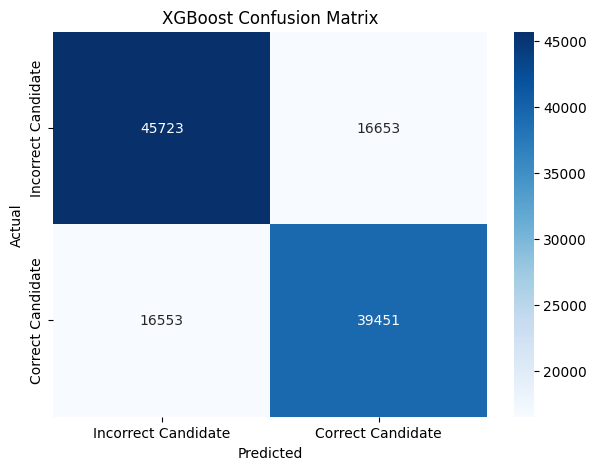

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Incorrect Candidate", "Correct Candidate"],
    yticklabels=["Incorrect Candidate", "Correct Candidate"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")

plt.show()

,Feature,Importance
4,heading_diff,0.451523
5,prev_dist,0.138844
7,heading_cos,0.072112
2,speed,0.067990
1,rank,0.066355
8,road_heading_sin,0.065168
6,heading_sin,0.042379
0,distance_m,0.035051
9,road_heading_cos,0.034854
3,time_gap,0.025724


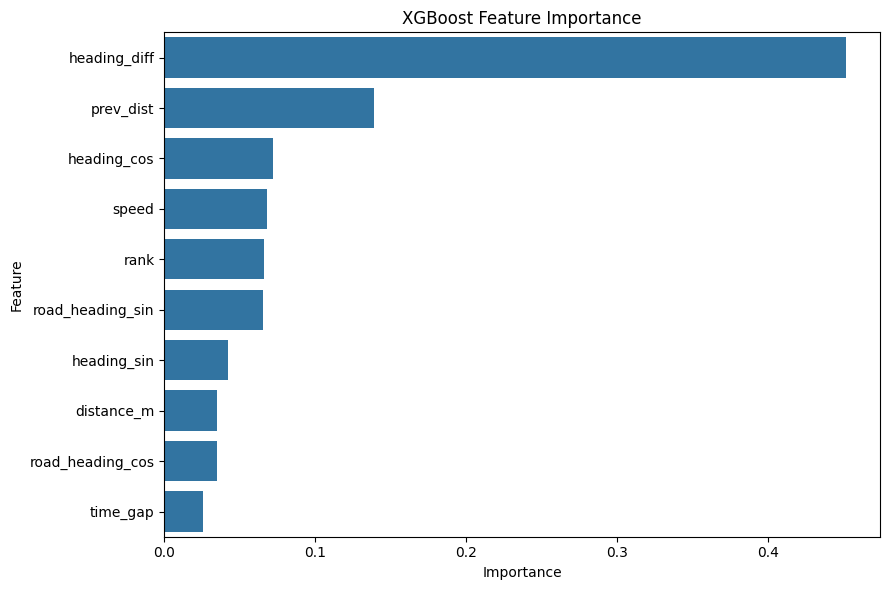

In [20]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("XGBoost Feature Importance")
plt.tight_layout()
plt.show()

In [21]:
import joblib

os.makedirs("/kaggle/working/models", exist_ok=True)

model_path = "/kaggle/working/models/pathsnap_xgboost.pkl"

joblib.dump(xgb_model, model_path, compress=3)

print("Model saved successfully!")
print("Location:", model_path)

print(
    "Size:",
    round(os.path.getsize(model_path) / (1024 * 1024), 2),
    "MB"
)

Model saved successfully!
Location: /kaggle/working/models/pathsnap_xgboost.pkl
Size: 0.46 MB


In [22]:
import json

config = {
    "model": "xgboost",
    "model_file": "pathsnap_xgboost.pkl",
    "features": features,
    "positive_class": 1
}

config_path = "/kaggle/working/models/xgboost_config.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("Feature configuration saved!")

Feature configuration saved!


In [23]:
loaded_model = joblib.load(model_path)

sample = X_val.iloc[:10]

predictions = loaded_model.predict(sample)
probabilities = loaded_model.predict_proba(sample)

print("Model loaded successfully!")
print("Sample predictions:", predictions)
print("Sample probabilities:\n", probabilities)

Model loaded successfully!
Sample predictions: [1 0 0 1 0 1 1 0 1 1]
Sample probabilities:
 [[0.43023127 0.5697687 ]
 [0.83312553 0.16687447]
 [0.6943295  0.30567047]
 [0.05104804 0.94895196]
 [0.9967873  0.00321267]
 [0.16603392 0.8339661 ]
 [0.04337317 0.95662683]
 [0.99673676 0.00326325]
 [0.15925664 0.84074336]
 [0.04061878 0.9593812 ]]
